# Check Data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import statsmodels.formula.api as smf
from scipy.stats import chisquare, chi2_contingency, bootstrap
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest, confint_proportions_2indep, proportion_confint
from statsmodels.stats.multitest import multipletests

os.makedirs("../images", exist_ok=True)

df = pd.read_csv("../data/raw/marketing_AB.csv")

In [2]:
# Drop the unecessary index column
df = df.drop(columns='Unnamed: 0')

In [3]:
df.head(10)

,user id,test group,converted,total ads,most ads day,most ads hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14
5,1137664,ad,False,734,Saturday,10
6,1116205,ad,False,264,Wednesday,13
7,1496843,ad,False,17,Sunday,18
8,1448851,ad,False,21,Tuesday,19
9,1446284,ad,False,142,Monday,14


In [4]:
# Make columns into snake case
df.columns = df.columns.str.replace(' ', '_')

In [5]:
# Checking shape, data types, nulls, and duplicates
print(df.shape)
print("\n")
print(df.dtypes)
print("\n")
print(df.isna().sum())
print("\n")
print(df.duplicated().sum())
print(df['user_id'].duplicated().sum())

(588101, 6)


user_id          int64
test_group         str
converted         bool
total_ads        int64
most_ads_day       str
most_ads_hour    int64
dtype: object


user_id          0
test_group       0
converted        0
total_ads        0
most_ads_day     0
most_ads_hour    0
dtype: int64


0
0


In [6]:
# Changing column converted to 0/1 boolean instead of true or false
df['converted'] = df['converted'].astype(int)

In [7]:
# Group sizes
print(df.groupby('test_group').size())
(df.groupby('test_group').size() / len(df)) * 100

test_group
ad     564577
psa     23524
dtype: int64


test_group
ad     96.000007
psa     3.999993
dtype: float64

In [8]:
summary = (
    df.groupby('test_group')['converted']
    .agg(total='count', conversions='sum', conversion_rate='mean')
    .reset_index()
)

summary['conversion_rate_pct'] = (summary['conversion_rate'] * 100).round(2)
summary

,test_group,total,conversions,conversion_rate,conversion_rate_pct
0,ad,564577,14423,0.025547,2.55
1,psa,23524,420,0.017854,1.79


# Sample Ratio Check

In [9]:
# The groups are very unbalanced (96% VS. 4%)
counts = df['test_group'].value_counts()
observed = [counts['ad'], counts['psa']]

total = sum(observed)
expected = [total * 0.96, total * 0.04]

chi2_stat, p_value = chisquare(f_obs = observed, f_exp=expected)

print(f"Observed [ad, psa]: {observed}")
print(f"Expected [ad, psa]: {expected}")
print(f"Chi2: {chi2_stat:.10f}, p-value: {p_value:.4f}")
# Chi square statistic is nearly 0 because the observed vs expected is nearly identical, p-value is well above
# any threshold to reject the null hypothesis (That there is no difference between the observed and expected groups).
# Which also means the small PSA group also limits the statistical power, having its variance contribution to be larger
# than the AD group's.

Observed [ad, psa]: [np.int64(564577), np.int64(23524)]
Expected [ad, psa]: [np.float64(564576.96), np.float64(23524.04)]
Chi2: 0.0000000708, p-value: 0.9998


# Hypothesis and Design

##### H0: Conversion rates are equal, Ha: Conversion rates are different
##### Will be using a two-sided test because:
1. Checks if ad performs differently from psa instead of strictly better or worse.
2. Prevents p-value from hitting tresholds easier, as one-sided tests cuts p-values in half.
3. More confidents when passing a two-sided test threshold.

In [10]:
alpha = 0.05
conversion_rate = df.groupby('test_group')['converted'].mean()
mde = 0.005
psa_control = conversion_rate['psa']
psa_treatment = conversion_rate['psa'] + mde

effect_size = proportion_effectsize(psa_treatment, psa_control)
power_analysis = NormalIndPower()

In [11]:
equal_split = power_analysis.solve_power(
    effect_size = effect_size,
    power = 0.80,
    alpha = alpha,
    ratio = 1.0,
    alternative ='two-sided'
)

actual_split = power_analysis.solve_power(
    effect_size = effect_size,
    power = 0.80,
    alpha = alpha,
    ratio = (564577 / 23524),
    alternative = 'two-sided'
)

In [12]:
n_trt_unequal = actual_split * (564577 / 23524)
print(f"50/50 Split -> Control: {math.ceil(equal_split):,}, Treatment: {math.ceil(equal_split):,} (Total: {math.ceil(equal_split)*2:,})")
print(f"96/4 Split  -> Control: {math.ceil(actual_split):,}, Treatment: {math.ceil(n_trt_unequal):,} (Total: {math.ceil(actual_split + n_trt_unequal):,})")
# Experiment requires 6,497 control (psa) and 155,921 (ad) users (162,418 total), where 50/50 split only required 24,948 total users.
# The observed dataset contains 23,524 control and 565,577 treatment users, which is approximately 3.62 times the 
# required sample size. Therefore, the experiment is adequately powered to reliably detect an effect of 0.5 percentage
# points or larger.

50/50 Split -> Control: 12,474, Treatment: 12,474 (Total: 24,948)
96/4 Split  -> Control: 6,497, Treatment: 155,921 (Total: 162,418)


# Main Significance Test
Testing whether the proportion of users who converted in the ad group is statistically different from the proportion of users who converted in the psa group

In [13]:
summary2 = df.groupby('test_group')['converted'].agg(['sum', 'count'])

ad_conv, ad_n = summary2.loc['ad', 'sum'], summary2.loc['ad', 'count']
psa_conv, psa_n = summary2.loc['psa', 'sum'], summary2.loc['psa', 'count']

ad_rate = ad_conv / ad_n
psa_rate = psa_conv / psa_n
abs_lift = ad_rate - psa_rate
rel_lift = (ad_rate - psa_rate) / psa_rate

In [14]:
z_stat, p_value = proportions_ztest(
    count = [ad_conv, psa_conv],
    nobs = [ad_n, psa_n],
    alternative = 'two-sided'
)

In [15]:
ci_low, ci_high = confint_proportions_2indep(
    count1 = ad_conv, nobs1 = ad_n,
    count2 = psa_conv, nobs2 = psa_n,
    method = 'wald'
)

In [16]:
print(f"Ad CR:          {ad_rate:.4%}")
print(f"PSA CR:         {psa_rate:.4%}")
print(f"Absolute Lift:  {abs_lift:+.4%} (95% CI: [{ci_low:+.4%}, {ci_high:+.4%}])")
print(f"Relative Lift:  {rel_lift:+.2%}")
print(f"Z-stat:         {z_stat:.4f}, p-value: {p_value:.4e}")

Ad CR:          2.5547%
PSA CR:         1.7854%
Absolute Lift:  +0.7692% (95% CI: [+0.5951%, +0.9434%])
Relative Lift:  +43.09%
Z-stat:         7.3701, p-value: 1.7053e-13


In [17]:
# Chi-square test for cross-checking
contingency_table = pd.crosstab(df['test_group'], df['converted'])
contingency_table

converted,0,1
test_group,,
ad,550154,14423
psa,23104,420


In [18]:
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table, correction = False)

print(f"Chi2 Stat: {chi2_stat:.4f}")
print(f"P-Value: {p_value:.4e}")
print(f"Degrees of Freedom: {dof}")
print(f"Expected Frequencies:\n {expected}")

Chi2 Stat: 54.3181
P-Value: 1.7053e-13
Degrees of Freedom: 1
Expected Frequencies:
 [[550327.71899045  14249.28100955]
 [ 22930.28100955    593.71899045]]


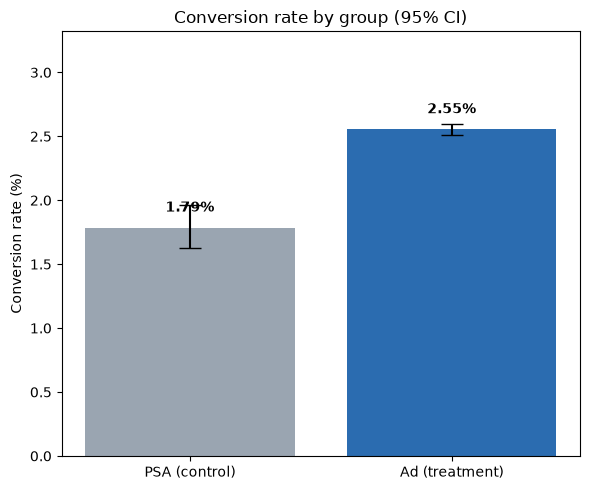

In [19]:
groups = ["PSA (control)", "Ad (treatment)"]
convs = [psa_conv, ad_conv]
ns = [psa_n, ad_n]

rates = [c / n * 100 for c, n in zip(convs, ns)]
cis = [proportion_confint(c, n, method="wilson") for c, n in zip(convs, ns)]
err_low = [r - lo * 100 for r, (lo, hi) in zip(rates, cis)]
err_high = [hi * 100 - r for r, (lo, hi) in zip(rates, cis)]

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(groups, rates, yerr=[err_low, err_high], capsize=8,
              color=["#9aa5b1", "#2b6cb0"])
for bar, r in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width() / 2, r + 0.1, f"{r:.2f}%",
            ha="center", va="bottom", fontweight="bold")
ax.set_ylabel("Conversion rate (%)")
ax.set_title("Conversion rate by group (95% CI)")
ax.set_ylim(0, max(rates) * 1.3)
plt.tight_layout()
plt.savefig("../images/conversion_by_group.png", dpi=150)
plt.show()

The results are statistically significance, users who saw the ad converted at a rate of 2.55%. compared to 1.79% of users who saw the public service announcement. Both two-proportion z-test and chi-square test of independence had a p-value below 0.0001, meaning there is virtually zero chance this difference occured by chance. Size of lift matters as well, the observed gain of +0.77 percentage points with a 95% confidence interval of [+0.5951%, +0.9434%], which beats the fixed Minimum Detectable Effect of 0.50 percentage points. 

Showing the ads drove a 43% relative increase in conversion rate, generating around 4,340 (14,423 - 10,080 expected baseline conversions/hypothetical) incremental conversions across the 564,577 users in the treatment group (ad) that would not have happened without the campaign.

# Bootstrap

In [20]:
control = df.loc[df['test_group'] == 'psa', 'converted'].to_numpy()
treatment = df.loc[df['test_group'] == 'ad', 'converted'].to_numpy()

In [21]:
def helper(ctrl, trt, axis=-1):
    return np.mean(trt, axis=axis) - np.mean(ctrl, axis=axis)

res = bootstrap(
    (control, treatment),
    helper,
    paired = False,
    n_resamples = 5000,
    batch = 100,
    method = 'percentile',
    confidence_level = 0.95,
    random_state = 42
)

In [22]:
print(f"Observed Lift: {helper(control, treatment):.4%}")
print(f"95% CI: [{res.confidence_interval.low:.4%}, {res.confidence_interval.high:.4%}]")

Observed Lift: 0.7692%
95% CI: [0.5941%, 0.9359%]


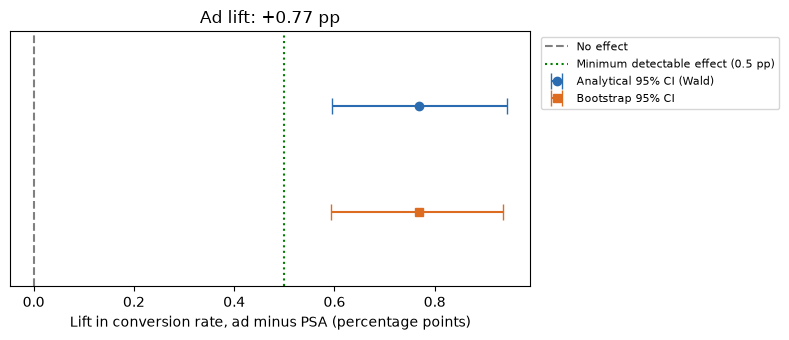

In [23]:
lift_pp = abs_lift * 100
boot_lo, boot_hi = res.confidence_interval.low * 100, res.confidence_interval.high * 100

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar([lift_pp], [1], xerr=[[lift_pp - ci_low * 100], [ci_high * 100 - lift_pp]],
            fmt="o", capsize=6, color="#2b6cb0", label="Analytical 95% CI (Wald)")
ax.errorbar([lift_pp], [0], xerr=[[lift_pp - boot_lo], [boot_hi - lift_pp]],
            fmt="s", capsize=6, color="#dd6b20", label="Bootstrap 95% CI")
ax.axvline(0, color="gray", linestyle="--", label="No effect")
ax.axvline(0.5, color="green", linestyle=":", label="Minimum detectable effect (0.5 pp)")
ax.set_yticks([])
ax.set_ylim(-0.7, 1.7)
ax.set_xlabel("Lift in conversion rate, ad minus PSA (percentage points)")
ax.set_title(f"Ad lift: {lift_pp:+.2f} pp")
ax.legend(loc="upper left", fontsize=8, bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig("../images/lift_with_ci.png", dpi=150, bbox_inches="tight")
plt.show()

# Segment Checks

In [24]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["most_ads_day"] = pd.Categorical(df["most_ads_day"], categories=day_order, ordered=True)

summary_by_days = (
    df.groupby(["most_ads_day", "test_group"], observed=False)["converted"]
      .agg(["count", "sum", "mean"])
      .unstack("test_group")
)
print(summary_by_days)

summary_by_hours = (
    df.groupby(["most_ads_hour", "test_group"], observed=False)["converted"]
      .agg(["count", "sum", "mean"])
      .unstack("test_group")
      .sort_index()
)
print(summary_by_hours)

              count         sum          mean          
test_group       ad   psa    ad psa        ad       psa
most_ads_day                                           
Monday        83571  3502  2778  79  0.033241  0.022559
Tuesday       74572  2907  2270  42  0.030440  0.014448
Wednesday     77418  3490  1963  55  0.025356  0.015759
Thursday      79077  3905  1711  79  0.021637  0.020230
Friday        88805  3803  1995  62  0.022465  0.016303
Saturday      78802  2858  1679  40  0.021307  0.013996
Sunday        82332  3059  2027  63  0.024620  0.020595
               count         sum          mean          
test_group        ad   psa    ad psa        ad       psa
most_ads_hour                                           
0               5309   227   102   0  0.019213  0.000000
1               4615   187    62   0  0.013434  0.000000
2               5152   181    39   0  0.007570  0.000000
3               2590    89    27   1  0.010425  0.011236
4                694    28    11   0  0.0

In [25]:
def segment_lift(data, col):
    rows = []
    for seg, g in data.groupby(col, observed=True):
        ad = g.loc[g["test_group"] == "ad", "converted"]
        psa = g.loc[g["test_group"] == "psa", "converted"]
        _, p = proportions_ztest([ad.sum(), psa.sum()], [len(ad), len(psa)])
        lo, hi = confint_proportions_2indep(ad.sum(), len(ad), psa.sum(), len(psa))
        rows.append({col: seg, "ad_n": len(ad), "psa_n": len(psa),
                     "ad_rate_pct": ad.mean() * 100, "psa_rate_pct": psa.mean() * 100,
                     "lift_pp": (ad.mean() - psa.mean()) * 100,
                     "ci_low_pp": lo * 100, "ci_high_pp": hi * 100, "p_raw": p})
    return pd.DataFrame(rows)

In [26]:
df["hour_block"] = pd.cut(df["most_ads_hour"], [-1, 5, 11, 17, 23],
                          labels=["night (0-5)", "morning (6-11)", "afternoon (12-17)", "evening (18-23)"])

by_day = segment_lift(df, "most_ads_day")
by_block = segment_lift(df, "hour_block")

planned = pd.concat([by_day.assign(family="day"), by_block.assign(family="hour block")],
                    ignore_index=True)
planned["p_adj"] = multipletests(planned["p_raw"], method="fdr_bh")[1]
planned.round(4)

,most_ads_day,ad_n,psa_n,ad_rate_pct,psa_rate_pct,lift_pp,ci_low_pp,ci_high_pp,p_raw,family,hour_block,p_adj
0,Monday,83571,3502,3.3241,2.2559,1.0683,0.5088,1.5272,0.0005,day,NaN,0.0011
1,Tuesday,74572,2907,3.0440,1.4448,1.5992,1.0826,1.9939,0.0000,day,NaN,0.0000
2,Wednesday,77418,3490,2.5356,1.5759,0.9597,0.4777,1.3400,0.0004,day,NaN,0.0010
3,Thursday,79077,3905,2.1637,2.0230,0.1407,-0.3603,0.5507,0.5548,day,NaN,0.5548
4,Friday,88805,3803,2.2465,1.6303,0.6162,0.1522,0.9863,0.0116,day,NaN,0.0141
5,Saturday,78802,2858,2.1307,1.3996,0.7311,0.2209,1.1153,0.0075,day,NaN,0.0103
6,Sunday,82332,3059,2.4620,2.0595,0.4025,-0.1736,0.8618,0.1572,day,NaN,0.1729
7,NaN,19102,735,1.3454,0.1361,1.2094,0.5603,1.4158,0.0045,hour block,night (0-5),0.0071
8,NaN,136526,5727,2.1161,1.2572,0.8589,0.5273,1.1280,0.0000,hour block,morning (6-11),0.0000
9,NaN,246925,10914,2.7668,2.0158,0.7511,0.4628,1.0069,0.0000,hour block,afternoon (12-17),0.0000


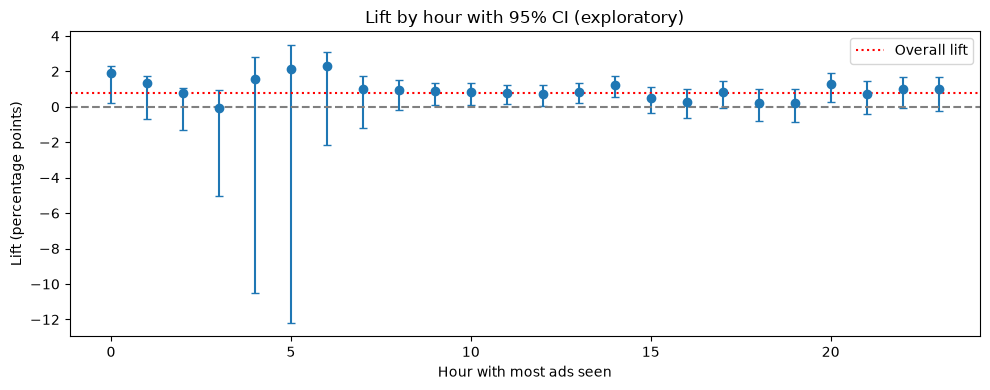

In [27]:
by_hour = segment_lift(df, "most_ads_hour")

fig, ax = plt.subplots(figsize=(10, 4))
x = by_hour["most_ads_hour"]
ax.errorbar(x, by_hour["lift_pp"],
            yerr=[by_hour["lift_pp"] - by_hour["ci_low_pp"], by_hour["ci_high_pp"] - by_hour["lift_pp"]],
            fmt="o", capsize=3)
ax.axhline(0, color="gray", linestyle="--")
ax.axhline(abs_lift * 100, color="red", linestyle=":", label="Overall lift")
ax.set_xlabel("Hour with most ads seen"); ax.set_ylabel("Lift (percentage points)")
ax.set_title("Lift by hour with 95% CI (exploratory)")
ax.legend()
plt.tight_layout()
plt.savefig("../images/lift_by_hour.png", dpi=150)
plt.show()

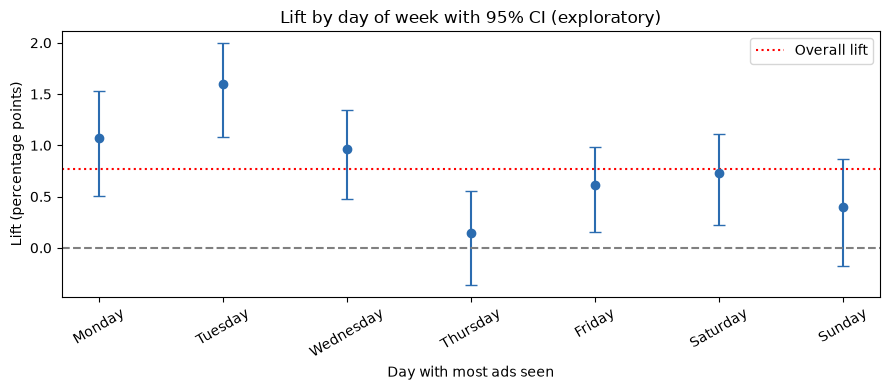

In [28]:
fig, ax = plt.subplots(figsize=(9, 4))
x = range(len(by_day))
ax.errorbar(x, by_day["lift_pp"],
            yerr=[by_day["lift_pp"] - by_day["ci_low_pp"],
                  by_day["ci_high_pp"] - by_day["lift_pp"]],
            fmt="o", capsize=4, color="#2b6cb0")
ax.axhline(0, color="gray", linestyle="--")
ax.axhline(abs_lift * 100, color="red", linestyle=":", label="Overall lift")
ax.set_xticks(list(x))
ax.set_xticklabels(by_day["most_ads_day"].astype(str), rotation=30)
ax.set_xlabel("Day with most ads seen")
ax.set_ylabel("Lift (percentage points)")
ax.set_title("Lift by day of week with 95% CI (exploratory)")
ax.legend()
plt.tight_layout()
plt.savefig("../images/lift_by_day.png", dpi=150)
plt.show()

In [29]:
df["ads_bin"] = pd.cut(df["total_ads"], [0, 5, 10, 25, 50, 100, np.inf],
                       labels=["1-5", "6-10", "11-25", "26-50", "51-100", "100+"])
(df.groupby(["ads_bin", "test_group"], observed=True)["converted"]
   .agg(["count", "mean"]).unstack("test_group").round(4))

count          mean        
test_group      ad   psa      ad     psa
ads_bin                                 
1-5         169962  7861  0.0025  0.0028
6-10         79537  3415  0.0049  0.0067
11-25       163135  6112  0.0102  0.0100
26-50        85740  3273  0.0354  0.0266
51-100       44149  1853  0.1163  0.0577
100+         22054  1010  0.1714  0.1188

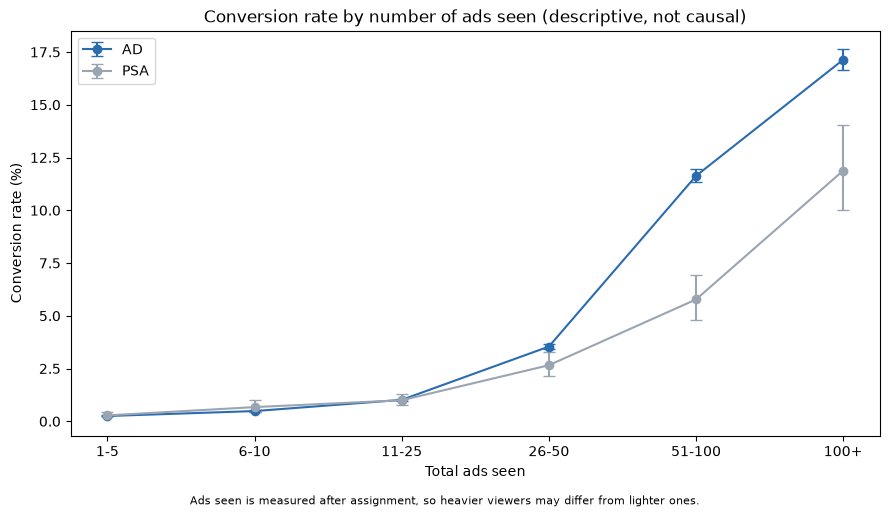

In [30]:
exp = (df.groupby(["ads_bin", "test_group"], observed=True)["converted"]
         .agg(["sum", "count"])
         .reset_index())

fig, ax = plt.subplots(figsize=(9, 5))
colors = {"ad": "#2b6cb0", "psa": "#9aa5b1"}
for grp, g in exp.groupby("test_group"):
    g = g.sort_values("ads_bin")
    r = g["sum"] / g["count"] * 100
    ci = [proportion_confint(s, n, method="wilson") for s, n in zip(g["sum"], g["count"])]
    lo = r - [c[0] * 100 for c in ci]
    hi = [c[1] * 100 for c in ci] - r
    ax.errorbar(g["ads_bin"].astype(str), r, yerr=[lo, hi], marker="o", capsize=4,
                label=grp.upper(), color=colors[grp])
ax.set_xlabel("Total ads seen")
ax.set_ylabel("Conversion rate (%)")
ax.set_title("Conversion rate by number of ads seen (descriptive, not causal)")
ax.legend()
fig.text(0.5, -0.02,
         "Ads seen is measured after assignment, so heavier viewers may differ from lighter ones.",
         ha="center", fontsize=8)
plt.tight_layout()
plt.savefig("../images/conversion_by_ad_exposure.png", dpi=150, bbox_inches="tight")
plt.show()

# Logistic Regression

In [31]:
model = smf.logit(
    "converted ~ C(test_group, Treatment(reference='psa')) + C(most_ads_day) + C(most_ads_hour)",
    data=df
).fit()

Optimization terminated successfully.
         Current function value: 0.116987
         Iterations 9


In [32]:
print(model.summary())

                           Logit Regression Results                           
Dep. Variable:              converted   No. Observations:               588101
Model:                          Logit   Df Residuals:                   588070
Method:                           MLE   Df Model:                           30
Date:                Mon, 23 Nov 2026   Pseudo R-squ.:                0.006740
Time:                        15:26:44   Log-Likelihood:                -68800.
converged:                       True   LL-Null:                       -69267.
Covariance Type:            nonrobust   LLR p-value:                5.006e-177
                                                      coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------------------
Intercept                                          -4.0677      0.112    -36.187      0.000      -4.288      -3.847
C(test_group, Treatm

In [33]:
or_table = np.exp(model.conf_int())
or_table["odds_ratio"] = np.exp(model.params)
or_table.columns = ["ci_low", "ci_high", "odds_ratio"]
print(or_table.loc[or_table.index.str.contains("test_group")])

                                                   ci_low   ci_high  \
C(test_group, Treatment(reference='psa'))[T.ad]  1.307658  1.590745   

                                                 odds_ratio  
C(test_group, Treatment(reference='psa'))[T.ad]    1.442273  
